## 1. Imports libraries

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load and combine the Assignment 1 data


In [2]:
DATA_DIR = Path("data")
math_path = DATA_DIR / "student-mat.csv"
port_path = DATA_DIR / "student-por.csv"

if not math_path.exists() or not port_path.exists():
    raise FileNotFoundError(
        "Could not find the CSV files. Place student-mat.csv and student-por.csv "
        "inside a folder named 'data' beside this notebook."
    )

math_data = pd.read_csv(math_path, sep=";")
port_data = pd.read_csv(port_path, sep=";")
math_data["subject"] = "Math"
port_data["subject"] = "Portuguese"
data = pd.concat([math_data, port_data], ignore_index=True)

data["performance"] = np.where(data["G3"] >= 10, "Pass", "Fail")
print(f"Mathematics records: {len(math_data)}")
print(f"Portuguese records: {len(port_data)}")
print(f"Combined records: {len(data)}")
print(f"Columns including target: {data.shape[1]}")
display(data.head())

Mathematics records: 395
Portuguese records: 649
Combined records: 1044
Columns including target: 35


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,subject,performance
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Math,Fail
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Math,Fail
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Math,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Math,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Math,Pass


## 3. Quick data checks and target distribution

This section confirms the target, missing values, duplicate rows, and class balance before modelling.

Missing values by column (only non-zero shown):


,missing_count


Exact duplicate rows: 0

Target counts:


,count
class,
Pass,814
Fail,230



Target percentages:


,percent
performance,
Pass,77.97
Fail,22.03


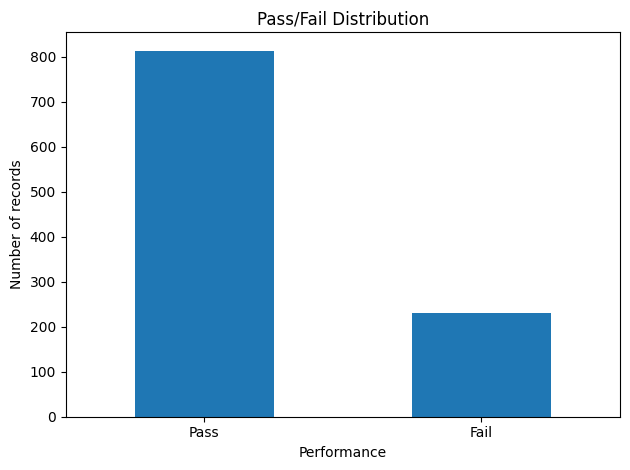

In [3]:
print("Missing values by column (only non-zero shown):")
display(data.isna().sum().loc[lambda s: s > 0].to_frame("missing_count"))
print("Exact duplicate rows:", int(data.duplicated().sum()))
print("\nTarget counts:")
display(data["performance"].value_counts().rename_axis("class").to_frame("count"))
print("\nTarget percentages:")
display((data["performance"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())
ax = data["performance"].value_counts().reindex(["Pass", "Fail"]).plot(kind="bar", rot=0)
ax.set_title("Pass/Fail Distribution")
ax.set_xlabel("Performance")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

## 4. Define prediction features and prevent leakage

`G1`, `G2`, and `G3` are excluded. `G3` directly defines the target, while `G1` and `G2` are prior grades that could dominate this particular exercise and produce an overly optimistic result. The remaining demographic, family, school, lifestyle, study, and subject variables are used as predictors.

In [4]:
target_col = "performance"
leakage_cols = ["G1", "G2", "G3", target_col]
X = data.drop(columns=leakage_cols)
y = data[target_col].map({"Fail": 0, "Pass": 1})

# Treat nominal / coded-category variables as categorical, not continuous numbers.
categorical_cols = [
    "school", "sex", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian", "schoolsup",
    "famsup", "paid", "activities", "nursery", "higher",
    "internet", "romantic", "subject"
]
categorical_cols = [c for c in categorical_cols if c in X.columns]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

assert not set(leakage_cols).intersection(X.columns), "Leakage columns found in features."
print("Feature count:", X.shape[1])
print("Categorical features:", categorical_cols)
print("Numeric features:", numeric_cols)
print("Target mapping: Fail=0, Pass=1")

Feature count: 31
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'subject']
Numeric features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Target mapping: Fail=0, Pass=1


## 5. Train/test split and leakage-free preprocessing

A stratified hold-out set is kept aside for final evaluation. The preprocessing objects are inside each scikit-learn pipeline, so cross-validation fits imputers, scaling, and encoding on each training fold only.

- Numeric features: median imputation, then standard scaling.
- Categorical features: most-frequent imputation, then one-hot encoding.
- Dense output is requested because `GaussianNB` requires dense input.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocess, numeric_cols),
        ("categorical", categorical_preprocess, categorical_cols)
    ],
    remainder="drop",
    sparse_threshold=0
)

print("Training records:", len(X_train))
print("Held-out test records:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename(index={0:"Fail",1:"Pass"}).to_frame("proportion"))

Training records: 835
Held-out test records: 209
Training class proportions:


,proportion
performance,
Pass,0.779641
Fail,0.220359


## 6. Train Naive Bayes and Decision Tree baselines

**Gaussian Naive Bayes** estimates class probabilities under a conditional-independence assumption and Gaussian distributions for transformed features.

**Decision Tree** learns feature-based splits. `class_weight="balanced"` helps account for any class imbalance, and a limited depth reduces uncontrolled complexity. Both models use the same preprocessing and same train/test split.

In [6]:
nb_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", GaussianNB())
])

tree_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

models = {
    "Gaussian Naive Bayes": nb_model,
    "Decision Tree": tree_model
}

## 7. Stratified 5-fold cross-validation

Cross-validation is performed on the training partition only. The final test partition is not used to choose models or tune their settings. `F1` refers to the Fail class (`pos_label=0`); ROC-AUC uses the probability of Pass (`1`) as the positive class.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "f1_fail": "f1",
    "roc_auc": "roc_auc"
}

# Since Fail is encoded as 0, sklearn's standard binary F1 scorer treats 1 as positive.
# Use an explicit scorer to calculate F1 for the Fail class.
from sklearn.metrics import make_scorer
scoring["f1_fail"] = make_scorer(f1_score, pos_label=0)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Fail F1 mean": scores["test_f1_fail"].mean(),
        "Fail F1 SD": scores["test_f1_fail"].std(),
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("Fail F1 mean", ascending=False)
display(cv_results.round(3))

,Model,Accuracy mean,Accuracy SD,Fail F1 mean,Fail F1 SD,ROC-AUC mean,ROC-AUC SD
1,Decision Tree,0.685,0.039,0.473,0.036,0.752,0.032
0,Gaussian Naive Bayes,0.764,0.026,0.471,0.089,0.731,0.056


## 8. Held-out test evaluation

After cross-validation, each model is fitted on the complete training partition and evaluated once on the held-out test partition. The results below are the final generalisation check for this assignment.

,Model,Accuracy,Fail F1,ROC-AUC (Pass)
1,Decision Tree,0.737,0.433,0.693
0,Gaussian Naive Bayes,0.746,0.391,0.701



Gaussian Naive Bayes
              precision    recall  f1-score   support

        Fail       0.41      0.37      0.39        46
        Pass       0.83      0.85      0.84       163

    accuracy                           0.75       209
   macro avg       0.62      0.61      0.62       209
weighted avg       0.74      0.75      0.74       209



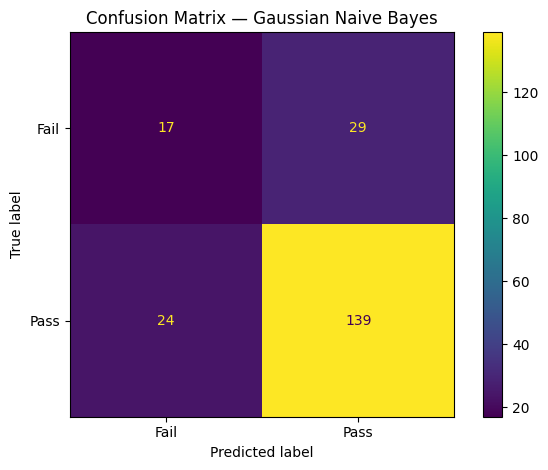


Decision Tree
              precision    recall  f1-score   support

        Fail       0.41      0.46      0.43        46
        Pass       0.84      0.82      0.83       163

    accuracy                           0.74       209
   macro avg       0.63      0.64      0.63       209
weighted avg       0.75      0.74      0.74       209



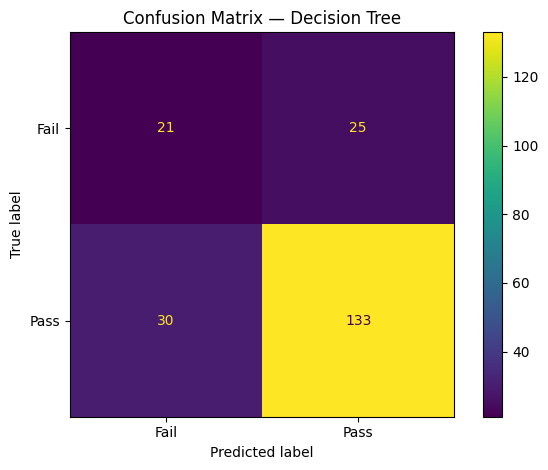

In [8]:
test_rows = []
fitted_models = {}
test_predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]  # probability of Pass
    test_predictions[name] = pred
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Fail F1": f1_score(y_test, pred, pos_label=0),
        "ROC-AUC (Pass)": roc_auc_score(y_test, prob)
    })

test_results = pd.DataFrame(test_rows).sort_values("Fail F1", ascending=False)
display(test_results.round(3))

for name, model in fitted_models.items():
    print("\n" + "=" * 65)
    print(name)
    print(classification_report(
        y_test, test_predictions[name],
        labels=[0, 1], target_names=["Fail", "Pass"], zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name],
        labels=[0, 1], display_labels=["Fail", "Pass"], values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 9. Hand-worked Gini split calculation

Worked case: split records by whether `failures == 0` or `failures > 0`. This uses a real feature and target from the project dataset. The calculation is shown from counts rather than relying on a library output.

For a node with class proportions \(p_k\), Gini impurity is:

\[
Gini(S)=1-\sum_k p_k^2
\]

The weighted impurity after splitting into groups \(S_j\) is:

\[
Gini_{split}=\sum_j 
rac{|S_j|}{|S|}Gini(S_j)
\]

The Gini gain is \(Gini(S)-Gini_{split}\). A larger positive gain means the split reduces class impurity more.

In [9]:
def gini_from_labels(labels):
    if len(labels) == 0:
        return 0.0
    proportions = pd.Series(labels).value_counts(normalize=True)
    return float(1 - (proportions ** 2).sum())

worked = data[["failures", "performance"]].copy()
groups = {
    "No previous failures (failures == 0)": worked[worked["failures"] == 0]["performance"],
    "One or more previous failures (failures > 0)": worked[worked["failures"] > 0]["performance"]
}
parent_gini = gini_from_labels(worked["performance"])
weighted_child_gini = 0.0
rows = []
n_total = len(worked)

for group_name, labels in groups.items():
    counts = labels.value_counts().reindex(["Fail", "Pass"], fill_value=0)
    impurity = gini_from_labels(labels)
    weighted_child_gini += (len(labels) / n_total) * impurity
    rows.append({
        "Group": group_name,
        "n": len(labels),
        "Fail count": int(counts["Fail"]),
        "Pass count": int(counts["Pass"]),
        "Gini": impurity,
        "Weighted Gini contribution": (len(labels) / n_total) * impurity
    })

gini_table = pd.DataFrame(rows)
gini_gain = parent_gini - weighted_child_gini
print("Parent counts:")
display(worked["performance"].value_counts().reindex(["Fail","Pass"], fill_value=0).to_frame("count"))
print(f"Parent Gini = 1 - (Fail proportion)^2 - (Pass proportion)^2 = {parent_gini:.4f}")
display(gini_table.round(4))
print(f"Weighted child Gini = {weighted_child_gini:.4f}")
print(f"Gini gain = Parent Gini - Weighted child Gini = {gini_gain:.4f}")

Parent counts:


,count
performance,
Fail,230
Pass,814


Parent Gini = 1 - (Fail proportion)^2 - (Pass proportion)^2 = 0.3435


,Group,n,Fail count,Pass count,Gini,Weighted Gini contribution
0,No previous failures (failures == 0),861,129,732,0.2548,0.2101
1,One or more previous failures (failures > 0),183,101,82,0.4946,0.0867


Weighted child Gini = 0.2968
Gini gain = Parent Gini - Weighted child Gini = 0.0467


## 10. Decision Tree

The tree's first split is shown as an example of a model-learned split after preprocessing. One-hot encoding means categorical features may appear as transformed feature names; the original-feature hand calculation above remains the transparent worked case requested by the brief.

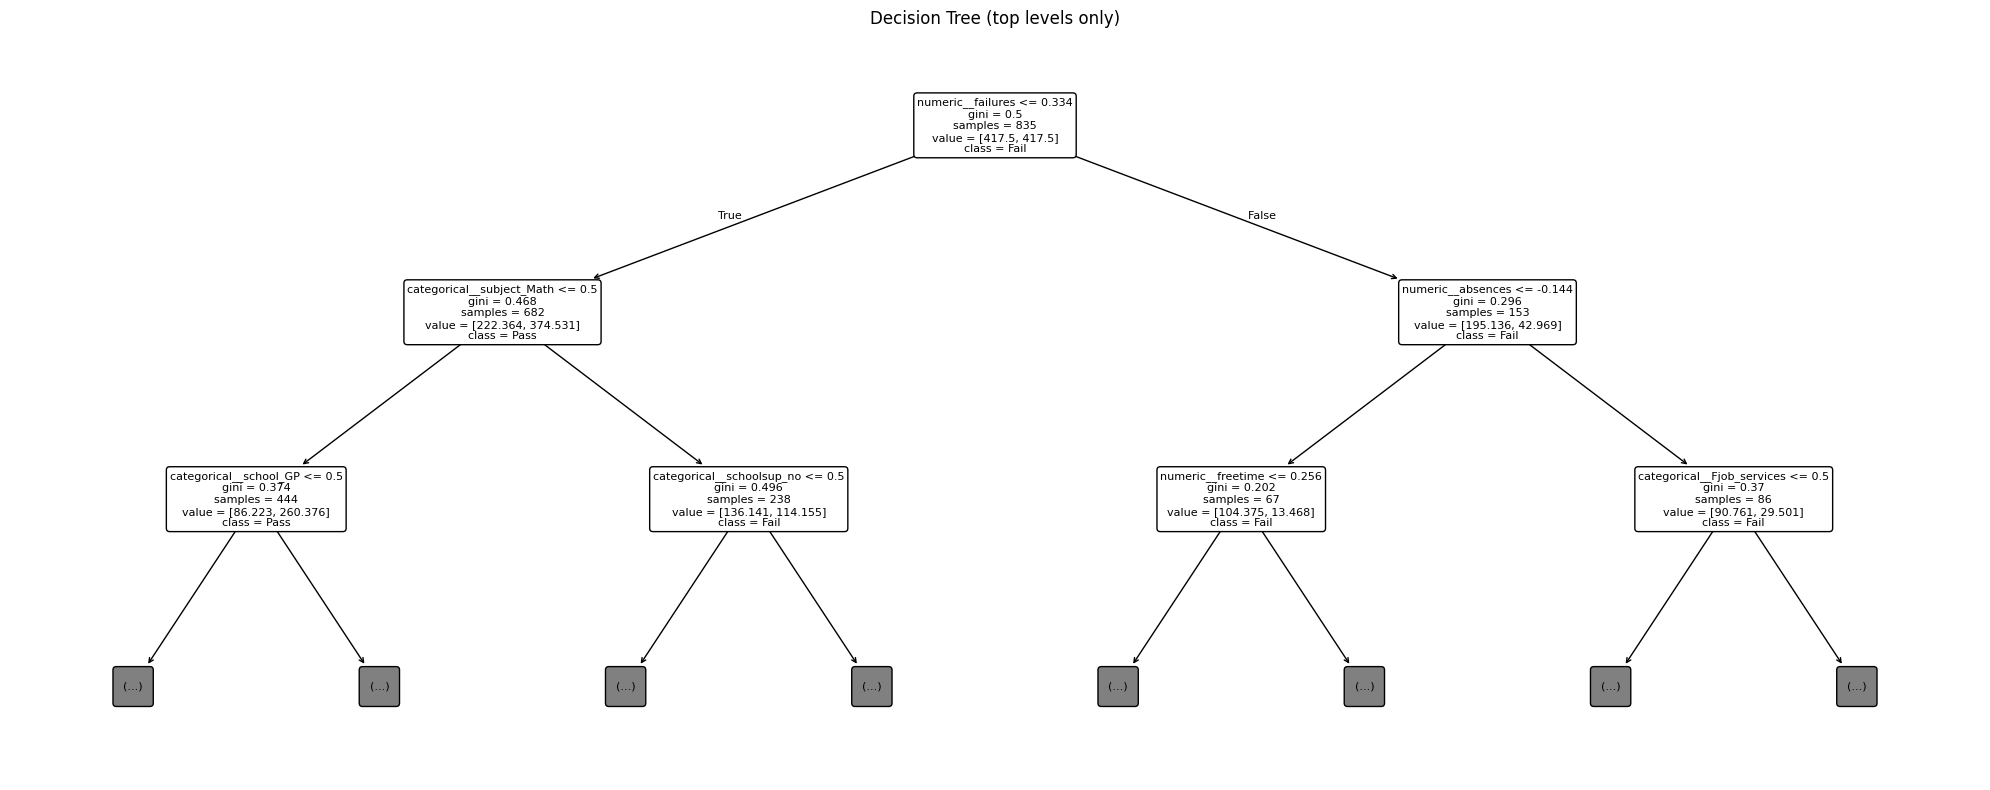

In [10]:
fitted_tree = fitted_models["Decision Tree"]
tree_preprocessor = fitted_tree.named_steps["preprocess"]
tree_estimator = fitted_tree.named_steps["model"]
try:
    transformed_names = tree_preprocessor.get_feature_names_out()
    plt.figure(figsize=(20, 8))
    plot_tree(
        tree_estimator,
        feature_names=transformed_names,
        class_names=["Fail", "Pass"],
        filled=False,
        rounded=True,
        max_depth=2,
        fontsize=8
    )
    plt.title("Decision Tree (top levels only)")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Tree plot could not be rendered in this environment:", exc)